# 06 · Terrain horizon (board task G2)

Checks `data/terrain.py` for the P0 site `site01_connecting_ridge`: 720 rays (0.5° step) through the PGDA 5 m DEM
(near field) and LOLA `LDEM_75S_120M` (far field, to 300 km), with lunar curvature.
**Done when:** the profile is plotted and distant ridges (e.g. toward Malapert) are visible.

Needs `uv run python -m data.pgda` and `uv run python -m data.lola` first (cached in `data/raw/`).

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import rasterio
from rasterio.windows import from_bounds
from data import lola, terrain
from data.horizons import SITES

SITE = "site01_connecting_ridge"
h = terrain.horizon(SITE)
az = np.arange(0, 360, terrain.AZ_STEP_DEG)
el, dist, near = h["elevation_deg"], h["distance_km"], h["near_field"]
print(f"ground {h['height_m']:.1f} m; LOLA - PGDA heights: bias {h['bias_m']:+.2f} m, RMS {h['rms_m']:.2f} m")
print(f"horizon {el.min():.2f} to {el.max():.2f} deg; set by PGDA at {near.mean():.0%} of azimuths, LOLA at the rest")

ground 1944.8 m; LOLA - PGDA heights: bias -0.35 m, RMS 2.20 m
horizon -3.22 to 2.28 deg; set by PGDA at 78% of azimuths, LOLA at the rest


## Where is Malapert?

Find the highest LOLA point within 40 km of (86°S, 0°E), the Malapert massif, then the azimuth and great-circle
distance from the site to it.

In [2]:
lat0, lon0 = np.radians(SITES[SITE])
with rasterio.open(lola.RAW / "LDEM_75S_120M.LBL") as ds:
    mx, my = terrain.TO_STEREO.transform(0.0, -86.0)
    win = from_bounds(mx - 40e3, my - 40e3, mx + 40e3, my + 40e3, ds.transform).round_offsets().round_lengths()
    z = ds.read(1, window=win) * ds.scales[0]
    r, c = np.unravel_index(np.argmax(z), z.shape)
    px, py = ds.window_transform(win) * (c + 0.5, r + 0.5)
plon, plat = terrain.TO_STEREO.transform(px, py, direction="INVERSE")
lat1, lon1 = np.radians(plat), np.radians(plon)
dlon = lon1 - lon0
mal_az = np.degrees(np.arctan2(np.sin(dlon) * np.cos(lat1),
                               np.cos(lat0) * np.sin(lat1) - np.sin(lat0) * np.cos(lat1) * np.cos(dlon))) % 360
mal_km = terrain.R_M / 1e3 * np.arccos(np.sin(lat0) * np.sin(lat1) + np.cos(lat0) * np.cos(lat1) * np.cos(dlon))
print(f"Malapert peak: {plat:.3f} deg, {plon % 360:.3f} deg E, {z.max():.0f} m; from {SITE}: az {mal_az:.1f} deg, {mal_km:.1f} km")
k = np.abs((az - mal_az + 180) % 360 - 180) <= 3
beyond = h["ray_distance_km"] > terrain.NEAR_KM
el_far = h["ray_elevation_deg"][:, beyond].max(axis=1)  # horizon if terrain within 12 km were flattened
kf = h["ray_distance_km"][beyond][h["ray_elevation_deg"][:, beyond].argmax(axis=1)]
print(pd.DataFrame({"azimuthDeg": az[k], "elevationDeg": el[k].round(2), "distanceKm": dist[k].round(2),
                    "beyond12kmDeg": el_far[k].round(2), "beyond12kmDistanceKm": kf[k].round(1)}).to_string(index=False))

Malapert peak: -85.988 deg, 2.063 deg E, 5172 m; from site01_connecting_ridge: az 144.0 deg, 134.5 km
 azimuthDeg  elevationDeg  distanceKm  beyond12kmDeg  beyond12kmDistanceKm
      141.5          0.79        0.04          -0.99                 133.8
      142.0          0.75        0.04          -0.99                 134.2
      142.5          0.71        0.04          -0.97                 134.0
      143.0          0.66        0.04          -0.95                 134.2
      143.5          0.62        0.04          -0.90                 134.5
      144.0          0.58        0.04          -0.84                 134.2
      144.5          0.54        0.04          -0.85                 133.0
      145.0          0.50        0.04          -0.85                 133.3
      145.5          0.45        0.04          -0.86                 133.6
      146.0          0.41        0.04          -0.92                 133.3
      146.5          0.37        0.04          -1.03                 133.

From Site01 the ground rises gently toward Malapert (about 3–4° slope at the DEM center), so terrain ~50 m
away sets the full horizon there and Malapert sits below it. The `beyond12kmDeg` column ignores terrain within
12 km: there the horizon toward 144° is set by terrain ~134 km away, the Malapert massif. So the far field resolves
it; a lander on a crest, or with a taller mast, would have Malapert as its horizon in that direction.

## Horizon profile

Top: horizon elevation per azimuth, coloured by which DEM sets it, and the horizon from terrain beyond 12 km only.
Bottom: distance to the terrain that sets the full horizon. The dashed line is the Malapert direction.

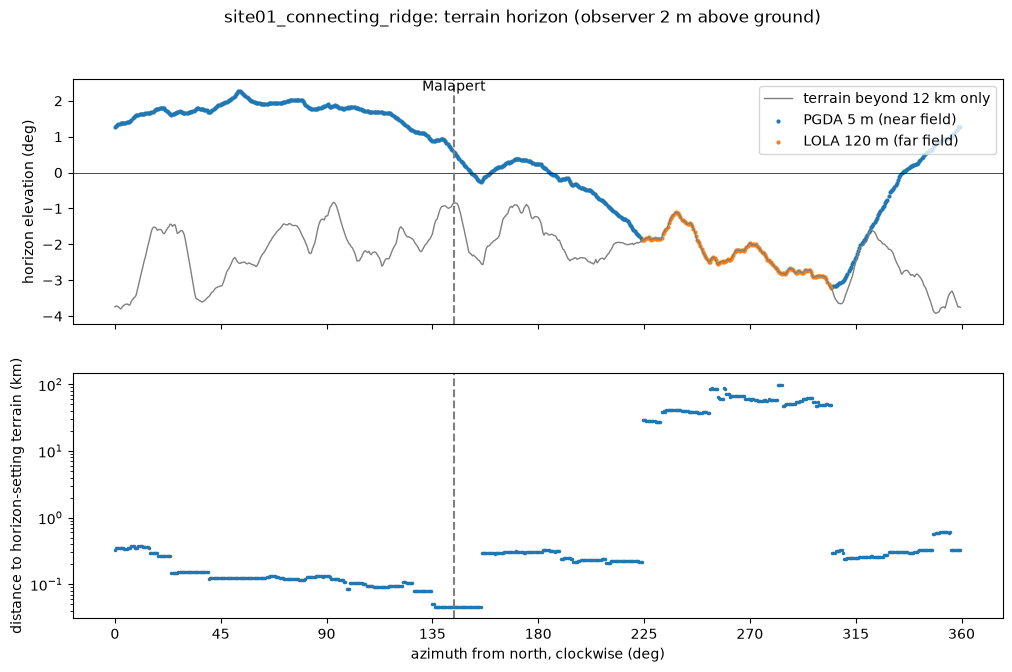

In [3]:
fig, (a1, a2) = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
a1.plot(az, el_far, color="gray", lw=1, label="terrain beyond 12 km only")
a1.scatter(az[near], el[near], s=4, label="PGDA 5 m (near field)")
a1.scatter(az[~near], el[~near], s=4, label="LOLA 120 m (far field)")
a1.axhline(0, color="k", lw=0.5)
a1.set_ylabel("horizon elevation (deg)")
a1.legend()
a2.semilogy(az, dist, ".", ms=3)
a2.set_ylabel("distance to horizon-setting terrain (km)")
a2.set_xlabel("azimuth from north, clockwise (deg)")
for a in (a1, a2):
    a.axvline(mal_az, ls="--", color="gray")
a1.annotate("Malapert", (mal_az, el.max()), ha="center")
a2.set_xticks(range(0, 361, 45))
fig.suptitle(f"{SITE}: terrain horizon (observer {terrain.OBSERVER_HEIGHT_M:g} m above ground)")
plt.show()

## Same numbers as a table (every 15°)

In [4]:
print(pd.DataFrame({"azimuthDeg": az, "elevationDeg": el.round(2), "distanceKm": dist.round(2),
                    "dem": np.where(near, "PGDA 5 m", "LOLA 120 m")})[::30].to_string(index=False))

 azimuthDeg  elevationDeg  distanceKm        dem
        0.0          1.28        0.33   PGDA 5 m
       15.0          1.66        0.30   PGDA 5 m
       30.0          1.67        0.16   PGDA 5 m
       45.0          1.90        0.12   PGDA 5 m
       60.0          1.95        0.12   PGDA 5 m
       75.0          2.02        0.12   PGDA 5 m
       90.0          1.89        0.14   PGDA 5 m
      105.0          1.75        0.10   PGDA 5 m
      120.0          1.51        0.10   PGDA 5 m
      135.0          0.88        0.05   PGDA 5 m
      150.0          0.11        0.04   PGDA 5 m
      165.0          0.20        0.30   PGDA 5 m
      180.0          0.23        0.30   PGDA 5 m
      195.0         -0.34        0.22   PGDA 5 m
      210.0         -0.95        0.21   PGDA 5 m
      225.0         -1.88       28.86 LOLA 120 m
      240.0         -1.18       41.58 LOLA 120 m
      255.0         -2.39       85.38 LOLA 120 m
      270.0         -1.96       59.40 LOLA 120 m
      285.0         

In [5]:
far = dist > 10
print(f"{far.mean():.0%} of azimuths are set by terrain beyond 10 km; farthest {dist.max():.0f} km "
      f"(range cast: {terrain.MAX_RANGE_KM:g} km)")

22% of azimuths are set by terrain beyond 10 km; farthest 99 km (range cast: 300 km)
